In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd, numpy as np
from IPython.display import Markdown, Image, display
P = ROOT / "data" / "processed"
F = ROOT / "docs" / "figures"
pd.options.display.float_format = "{:,.4f}".format
def table(name): return pd.read_csv(P / name)
def summary(name): return json.loads((P / name).read_text())
def fig(name): display(Image(filename=str(F / name)))
print("Simulated data. Every number below is read from executed pipeline outputs.")


Simulated data. Every number below is read from executed pipeline outputs.


# M5. Constrained price optimisation (Simulated data)

Decision variables are the percentage price changes for new business, $x_s$, and renewal, $y_s$, in each of the $S=15$ segments, bounded by $\pm 5\%$.

$$\max_{x,y}\; \sum_{s}\Big[ N_s(x_s)\,\big(P_s(1+x_s) - c_s\big) + R_s(y_s)\,\big(P^{R}_s(1+y_s) - c^{R}_s\big) \Big]$$

where $N_s$ and $R_s$ are expected policies from the experiment-calibrated GLMs, $P$ are average premiums and $c$ are the fixed unit costs from the configuration (never fitted).

Subject to:

$$\frac{\text{Contribution}(x,y)}{\text{GWP}(x,y)} \ge m_{\min}, \qquad \sum_s N_s(x_s) \ge v_N \sum_s N_s(0), \qquad \sum_s R_s(y_s) \ge v_R \sum_s R_s(0)$$

$$\bar{r}_s(x_s) - \bar{r}_s(0) \le \Delta_{\text{rank}} \;\;\forall s, \qquad y_s \le \bar{y} \;\;\forall s, \qquad -0.05 \le x_s, y_s \le 0.05$$

with $\bar r_s$ the mean market rank, $\Delta_{\text{rank}}$ the rank deterioration cap and $\bar y$ the renewal price change cap. Rank is a step function of price, so the solver uses a logistic smoothing of width $w$ and the result is re-evaluated with exact rank, tightening until exactly feasible. SLSQP is used with analytic Jacobians. Parameters are in `config/calibration.yaml` with status `illustrative_assumption`.

In [2]:
s = summary("m5_summary.json")
pd.DataFrame({"converged": s["converged"], "iterations": s["iterations"], "exact min slack": s["exact_min_constraint_slack"]})

,converged,iterations,exact min slack
calibrated,True,4,0.0000
observational,True,4,0.0000


In [3]:
table("m5_baseline_vs_optimised__simulated_data.csv")

,optimised_with,evaluated_on,scenario,nb_conversion,nb_policies,nb_gwp,nb_contribution,renewal_policies,renewal_gwp,renewal_contribution,total_policies,total_gwp,total_contribution,margin
0,calibrated,model,baseline,0.0813,"1,668.2800","1,025,876.1687","117,012.0835","8,044.9214","5,380,828.6853","1,365,700.9010","9,713.2014","6,406,704.8540","1,482,712.9845",0.2314
1,calibrated,model,optimised,0.0781,"1,601.9122","1,025,024.1473","130,626.6834","7,893.3593","5,366,918.0674","1,428,840.2765","9,495.2715","6,391,942.2148","1,559,466.9599",0.2440
2,calibrated,true_process,baseline,0.0805,"1,650.8795","1,017,319.5771","118,247.0768","8,039.5597","5,365,355.7291","1,358,857.6124","9,690.4392","6,382,675.3062","1,477,104.6892",0.2314
3,calibrated,true_process,optimised,0.0766,"1,570.9788","1,005,972.8084","129,759.5447","7,832.2912","5,310,356.9790","1,409,895.1562","9,403.2699","6,316,329.7875","1,539,654.7009",0.2438
4,observational,model,baseline,0.0813,"1,668.2800","1,025,876.1687","117,012.0835","8,044.9214","5,380,828.6853","1,365,700.9010","9,713.2014","6,406,704.8540","1,482,712.9845",0.2314
5,observational,model,optimised,0.0779,"1,597.5840","1,010,631.2828","130,322.5663","7,893.3593","5,366,918.0674","1,428,840.2765","9,490.9433","6,377,549.3503","1,559,162.8428",0.2445
6,observational,true_process,baseline,0.0805,"1,650.8795","1,017,319.5771","118,247.0768","8,039.5597","5,365,355.7291","1,358,857.6124","9,690.4392","6,382,675.3062","1,477,104.6892",0.2314
7,observational,true_process,optimised,0.0744,"1,526.8872","972,918.7384","128,304.4297","7,832.2912","5,310,356.9790","1,409,895.1562","9,359.1783","6,283,275.7174","1,538,199.5859",0.2448


In [4]:
display(Markdown(f"Contribution gain on the model: **{s['contribution_gain_calibrated']['model']:.2%}**. Evaluated against the simulated true process: **{s['contribution_gain_calibrated']['true_process']:.2%}**. Using the uncalibrated observational GLM instead gives a model gain of {s['contribution_gain_observational']['model']:.2%} and a true-process gain of {s['contribution_gain_observational']['true_process']:.2%}."))

Contribution gain on the model: **5.18%**. Evaluated against the simulated true process: **4.23%**. Using the uncalibrated observational GLM instead gives a model gain of 5.16% and a true-process gain of 4.14%.

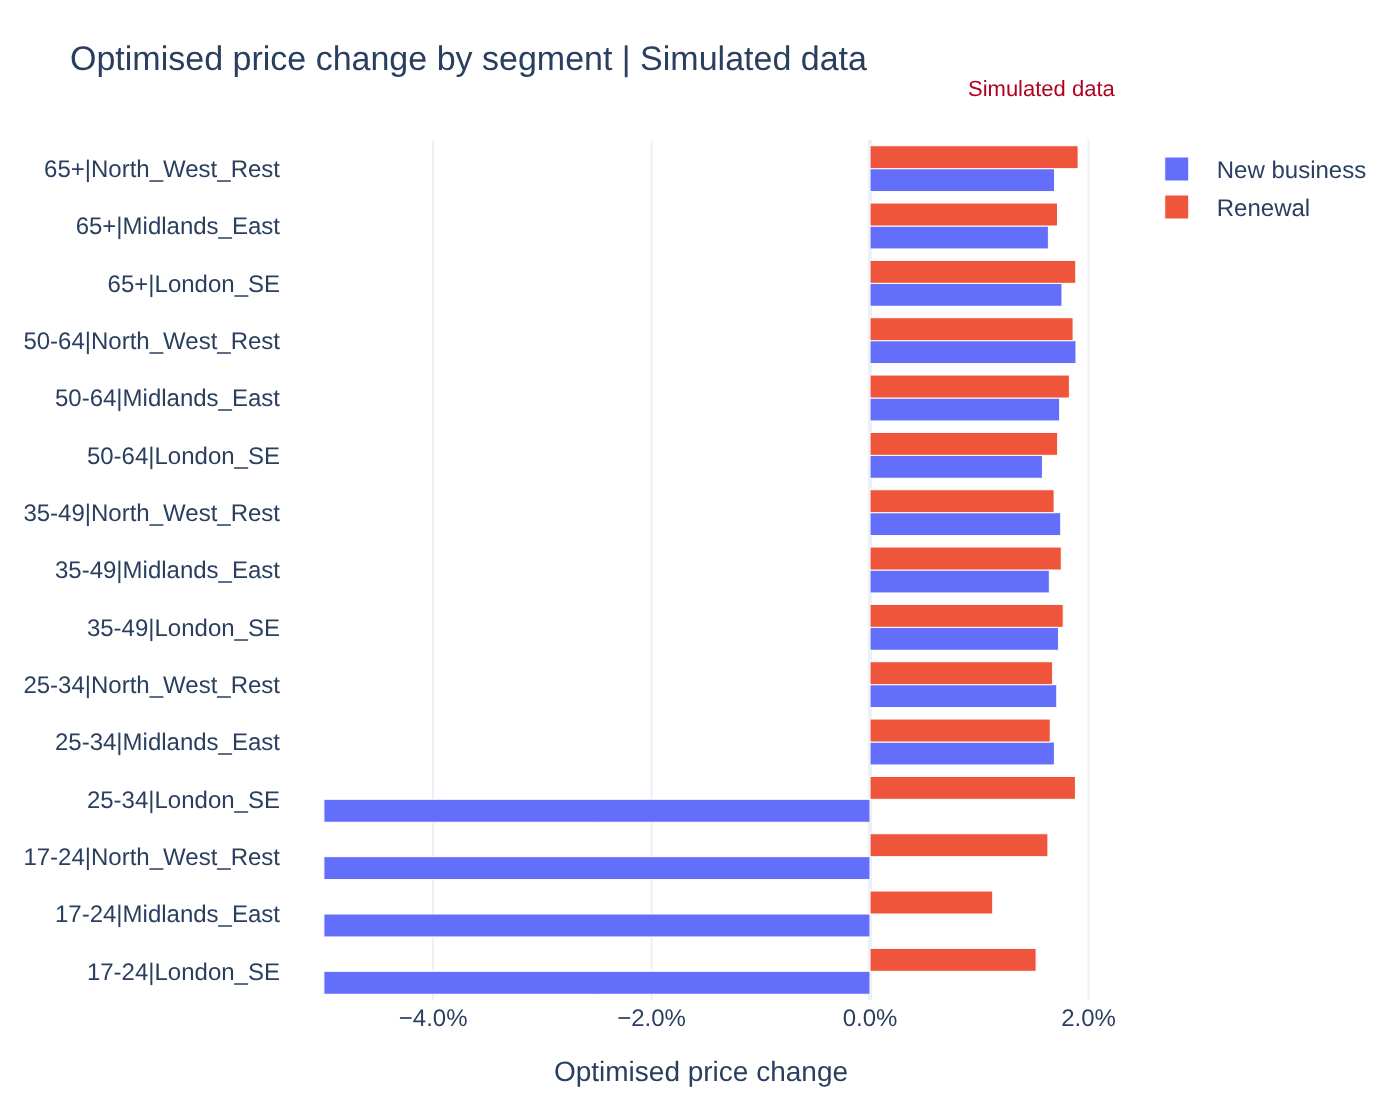

In [5]:
fig("m5_segment_price_changes__simulated_data.png")

In [6]:
table("m5_segment_decisions_calibrated__simulated_data.csv")

,segment,nb_price_change,renewal_price_change,nb_quotes,nb_conversion_base,nb_conversion_opt,nb_policies_base,nb_policies_opt,nb_contribution_base,nb_contribution_opt,nb_rank_base,nb_rank_opt,renewal_policies_base,renewal_policies_opt,renewal_contribution_base,renewal_contribution_opt,renewal_avg_change_opt,nb_action,renewal_action
0,17-24|London_SE,-0.0500,0.0152,520.0000,0.0261,0.0387,13.5956,20.1097,"7,280.9144","8,939.0382",6.7885,5.6731,188.3878,184.1345,"117,190.2926","119,215.4251",0.0999,discount,increase
1,17-24|Midlands_East,-0.0500,0.0112,504.0000,0.0455,0.0684,22.9465,34.4734,"7,145.5928","8,350.3891",5.7401,4.5258,152.2172,149.5701,"65,365.8809","66,333.5596",0.0999,discount,increase
2,17-24|North_West_Rest,-0.0500,0.0163,646.0000,0.0466,0.0697,30.1202,45.0318,"8,163.4563","9,355.2401",5.7136,4.4706,210.4032,205.4322,"77,973.6629","80,011.0635",0.0999,discount,increase
3,25-34|London_SE,-0.0500,0.0188,"1,436.0000",0.0581,0.0817,83.4498,117.2572,"15,794.2673","16,361.1994",5.2994,4.1260,512.5475,500.6084,"144,737.0129","149,964.8957",0.0920,discount,increase
4,25-34|Midlands_East,0.0169,0.0165,"1,331.0000",0.0926,0.0835,123.2513,111.2023,"9,342.3705","9,786.0617",4.3216,4.7190,540.4929,529.3505,"87,944.5765","91,897.4272",0.0900,increase,increase
5,25-34|North_West_Rest,0.0171,0.0167,"1,758.0000",0.0921,0.0827,161.8709,145.4592,"9,868.1548","10,589.9828",4.2600,4.6542,623.2943,611.0271,"89,740.8589","94,307.1008",0.0898,increase,increase
6,35-49|London_SE,0.0173,0.0177,"1,987.0000",0.0602,0.0554,119.6400,110.1399,"17,478.5582","17,691.1989",5.5606,5.9592,795.7757,779.8124,"177,164.2796","184,011.1519",0.0812,increase,increase
7,35-49|Midlands_East,0.0164,0.0175,"1,968.0000",0.0847,0.0775,166.6896,152.5700,"8,582.2583","9,457.4792",4.6657,5.0549,691.6304,678.4639,"83,086.2299","87,936.9635",0.0810,increase,increase
8,35-49|North_West_Rest,0.0175,0.0169,"2,336.0000",0.0903,0.0825,210.9401,192.8313,"7,595.9866","8,914.1078",4.3866,4.7830,964.8407,947.4147,"105,708.2685","111,960.3518",0.0780,increase,increase
9,50-64|London_SE,0.0158,0.0172,"1,628.0000",0.0777,0.0717,126.4411,116.6468,"9,679.2753","10,275.1422",4.6259,5.0246,700.6019,688.5988,"104,899.6222","110,764.8156",0.0787,increase,increase


In [7]:
table("m5_constraints__simulated_data.csv")

,constraint,slack,binding
0,portfolio_margin_floor,0.2402,False
1,nb_volume_floor,0.0100,False
2,renewal_volume_floor,0.0112,False
3,nb_rank_cap:17-24|London_SE,1.5152,False
4,nb_rank_cap:17-24|Midlands_East,1.6259,False
5,nb_rank_cap:17-24|North_West_Rest,1.6410,False
6,nb_rank_cap:25-34|London_SE,1.5715,False
7,nb_rank_cap:25-34|Midlands_East,-0.0000,True
8,nb_rank_cap:25-34|North_West_Rest,-0.0000,True
9,nb_rank_cap:35-49|London_SE,0.0000,True


## Limitations

- Contribution gains are measured on the test-period planning book of simulated quotes and only show direction and rough size under the stated assumptions.
- Many rank caps bind. The decision is driven as much by the cap as by the economics, so the cap value is the key sensitivity.
- Unit cost is a fixed configuration input. No claims model informs it.